# 5. 단순 선형 회귀와 Diabetes 데이터

BMI 한 열로 연속적인 당뇨 진행도를 예측합니다. 입력은 열 하나인 2차원 배열로 유지합니다.

원본 노트북 Lv2_Python_1119_Regression.diabetes.ipynb

**선형회귀모델** <br>
당뇨병 데이터셋(Diabetes dataset) 사용 <br>
타겟 변수(당뇨병 진행도) 예측

In [ ]:
# 패키지 Import
import numpy as np
from sklearn import datasets, linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [ ]:
import pandas as pd
from sklearn.datasets import load_diabetes

# 데이터셋 로드
diabetes_data = load_diabetes()

# 데이터셋을 DataFrame으로 변환
df_diabetes = pd.DataFrame(data=diabetes_data.data, columns=diabetes_data.feature_names)

# 타겟(목표 변수) 추가
df_diabetes['target'] = diabetes_data.target

# DataFrame 확인
df_diabetes.head()

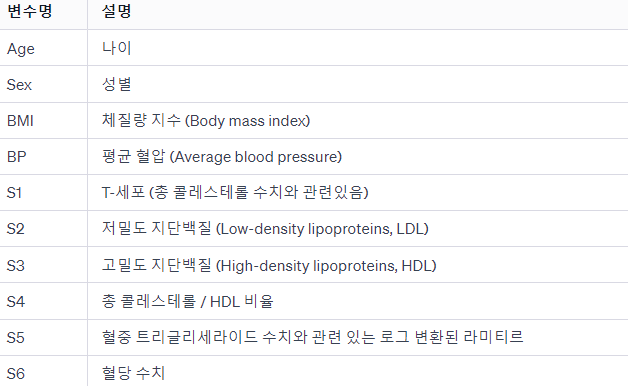

In [ ]:
# diabetes dataset 로드
diabetes_X, diabetes_y = datasets.load_diabetes(return_X_y=True)

# BMI(체질량지수) 만 선택
# 속성을 2개 이상 선택하면 자동으로 2차원 형태
diabetes_X = diabetes_X[:, np.newaxis, 2]   # 전체 데이터셋에서 세 번째 특성을 선택 BMI(체질량지수)

# NumPy 배열 슬라이싱.. 쉼표(,)로 구분된 각 위치는 행과 열의 차원을 의미
# 첫 번째 (:): 모든 행 선택
# 두번째 (np.newaxis) : 새로운 차원(축) 추가 -> 2차원 형태로 변환. ML에서 입력 데이터(X)가 2차원 행렬 형태 (샘플 수, 특성 수)여야
# 세 번째 (2): 인덱스 번호가 2인 열(즉 세 번째 특성인 BMI) 선택

## 2 차원 유지.
# 슬라이싱 범위 지정: diabetes_X[:, 2:3]
# reshape 함수 사용: diabetes_X[:, 2].reshape(-1, 1)

In [ ]:
diabetes_X.shape

In [ ]:
# diabetes_X_temp, diabetes_y_temp = datasets.load_diabetes(return_X_y=True)
# diabetes_X_temp = diabetes_X_temp[:, 2]
# diabetediabetes_X_temps_X2.shape

In [ ]:
diabetes_X

In [ ]:
# diabetes_X2 = df_diabetes[['age', 'bp', 's4']]

In [ ]:
# diabetes_X2

In [ ]:
# training/testing sets 분활
diabetes_X_train, diabetes_X_test, diabetes_y_train, diabetes_y_test = train_test_split(
    diabetes_X, diabetes_y, test_size=0.2, random_state=42
)

In [ ]:
# 선형 회귀 모델(객체) 생성
regr = linear_model.LinearRegression()

In [ ]:
# 모델 훈련
# BMI(체질량지수)만 사용하여 당뇨 진행도 설명
regr.fit(diabetes_X_train, diabetes_y_train)

In [ ]:
# 예측 수행
diabetes_y_pred = regr.predict(diabetes_X_test)

In [ ]:
# The coefficients 회귀 계수
print('Coefficients: \n', regr.coef_)

# The mean squared error
print('Mean squared error: %.2f'
      % mean_squared_error(diabetes_y_test, diabetes_y_pred))

#  결정 계수
print('Coefficient of determination: %.2f'
      % r2_score(diabetes_y_test, diabetes_y_pred))

In [ ]:
# 예측 Vs 결과 시각
plt.scatter(diabetes_X_test, diabetes_y_test, color='black')
plt.plot(diabetes_X_test, diabetes_y_pred, color='blue', linewidth=3)

plt.xticks(())
plt.yticks(())

plt.show()